In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('Dataset .csv')

# Verify data load
print("Dataset Shape:", df.shape)
df.head(2)

Dataset Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591


--- Rating Text Distribution ---
Rating text
Average      3737
Not rated    2148
Good         2100
Very Good    1079
Excellent     301
Poor          186
Name: count, dtype: int64

Average Rating Text Length: 7.02 characters


/tmp/ipykernel_1519/1481269835.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Aggregate rating', y='Review Length', palette='mako')


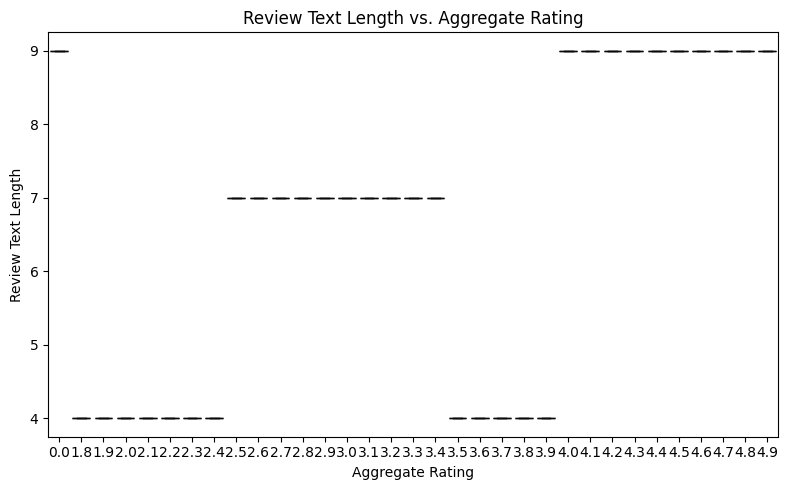

In [2]:
# Task 1: Restaurant Reviews Analysis

# 1. Frequency of Rating Text keywords
print("--- Rating Text Distribution ---")
print(df['Rating text'].value_counts())

# 2. Review Length Analysis (using 'Rating text')
df['Review Length'] = df['Rating text'].astype(str).apply(len)
avg_length = df['Review Length'].mean()
print(f"\nAverage Rating Text Length: {avg_length:.2f} characters")

# 3. Relationship between Review Text Length and Aggregate Rating
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Aggregate rating', y='Review Length', palette='mako')
plt.title('Review Text Length vs. Aggregate Rating')
plt.xlabel('Aggregate Rating')
plt.ylabel('Review Text Length')
plt.tight_layout()
plt.savefig('task1_review_length_vs_rating.png')
plt.show()

--- Highest Voted Restaurant ---
Name: Toit
Votes: 10934
Rating: 4.8

--- Lowest Voted Restaurant ---
Name: Cantinho da Gula
Votes: 0
Rating: 0.0

Correlation between Votes and Aggregate Rating: 0.3137


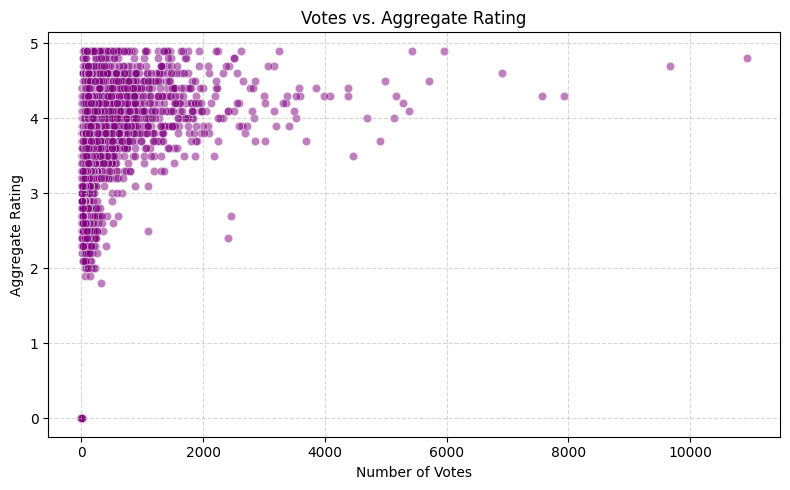

In [3]:
# Task 2: Votes Analysis

# 1. Highest and Lowest Voted Restaurants
highest_voted = df.loc[df['Votes'].idxmax()]
lowest_voted = df.loc[df['Votes'].idxmin()]

print("--- Highest Voted Restaurant ---")
print(f"Name: {highest_voted['Restaurant Name']}")
print(f"Votes: {highest_voted['Votes']}")
print(f"Rating: {highest_voted['Aggregate rating']}")

print("\n--- Lowest Voted Restaurant ---")
print(f"Name: {lowest_voted['Restaurant Name']}")
print(f"Votes: {lowest_voted['Votes']}")
print(f"Rating: {lowest_voted['Aggregate rating']}")

# 2. Correlation between Votes and Aggregate Rating
correlation = df['Votes'].corr(df['Aggregate rating'])
print(f"\nCorrelation between Votes and Aggregate Rating: {correlation:.4f}")

# 3. Scatter Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Votes', y='Aggregate rating', alpha=0.5, color='purple')
plt.title('Votes vs. Aggregate Rating')
plt.xlabel('Number of Votes')
plt.ylabel('Aggregate Rating')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('task2_votes_vs_rating.png')
plt.show()

--- Percentage of Online Delivery by Price Range (%) ---
Has Online delivery     No    Yes
Price range                      
1                    84.23  15.77
2                    58.69  41.31
3                    70.81  29.19
4                    90.96   9.04

--- Percentage of Table Booking by Price Range (%) ---
Has Table booking     No    Yes
Price range                    
1                  99.98   0.02
2                  92.32   7.68
3                  54.26  45.74
4                  53.24  46.76


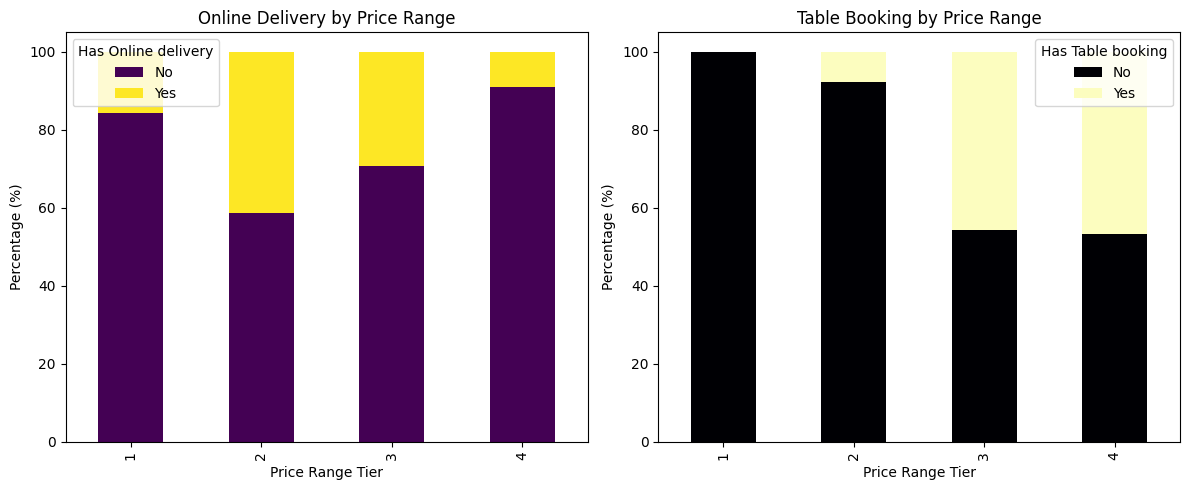

In [4]:
# Task 3: Price Range vs. Online Delivery & Table Booking

# 1. Online Delivery availability by Price Range
delivery_by_price = pd.crosstab(df['Price range'], df['Has Online delivery'], normalize='index') * 100
print("--- Percentage of Online Delivery by Price Range (%) ---")
print(delivery_by_price.round(2))

# 2. Table Booking availability by Price Range
booking_by_price = pd.crosstab(df['Price range'], df['Has Table booking'], normalize='index') * 100
print("\n--- Percentage of Table Booking by Price Range (%) ---")
print(booking_by_price.round(2))

# 3. Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

delivery_by_price.plot(kind='bar', stacked=True, ax=axes[0], colormap='viridis')
axes[0].set_title('Online Delivery by Price Range')
axes[0].set_xlabel('Price Range Tier')
axes[0].set_ylabel('Percentage (%)')

booking_by_price.plot(kind='bar', stacked=True, ax=axes[1], colormap='magma')
axes[1].set_title('Table Booking by Price Range')
axes[1].set_xlabel('Price Range Tier')
axes[1].set_ylabel('Percentage (%)')

plt.tight_layout()
plt.savefig('task3_price_vs_services.png')
plt.show()